# Do gas prices sink the president's party in midterms?

This notebook walks through the analysis step by step. The pipeline scripts in `src/` produce the same results; this is the readable version.

**Question:** do rising gas prices predict larger House losses for the president's party in U.S. midterm elections (1978–2022)?

In [1]:
import sys; sys.path.insert(0, '../src')
import pandas as pd, statsmodels.formula.api as smf, matplotlib.pyplot as plt
nat = pd.read_csv('../data/processed/national.csv')
panel = pd.read_csv('../data/processed/state_panel.csv')
nat

,year,president,pres_party,approval,pres_party_share,swing,seat_change,gas_price_oct,real_gas_price_oct,gas_chg_2y,gas_chg_1y,crude_chg_2y,inflation_1y,unemp_oct,unemp_chg_2y
0,1978,Carter,D,49,52.963788,-1.827029,-14,0.690,3.246023,-5.342618,-4.745470,-2.770651,8.928571,5.541176,-1.490196
1,1982,Reagan,R,42,46.130151,-4.126511,-27,1.295,4.162779,-10.536864,-10.160422,-6.576014,5.139186,9.780392,2.545098
2,1986,Reagan,R,63,47.071890,-3.244205,-5,0.831,2.378212,-34.381306,-31.981262,-56.378041,1.471941,6.831373,-0.278431
3,1990,G.H.W. Bush,R,58,46.582540,-2.015834,-8,1.378,3.258315,29.646406,26.237140,130.234660,6.289809,5.737255,0.380392
4,1994,Clinton,D,46,48.313644,-4.474226,-54,1.152,2.432408,-5.314886,-0.379912,-20.626202,2.608099,5.354902,-1.394118
5,1998,Clinton,D,66,50.754415,0.933092,4,1.042,2.005621,-18.029002,-17.330820,-47.262887,1.485149,4.350980,-0.694118
6,2002,G.W. Bush,R,63,51.662637,1.779344,8,1.449,2.522874,-10.798180,4.275169,-16.340414,2.025886,5.333333,1.447059
7,2006,G.W. Bush,R,38,47.888972,-2.503762,-30,2.272,3.553957,5.928067,-19.471187,10.819619,1.305221,4.384314,-0.721569
8,2010,Obama,D,45,47.886868,-5.959798,-64,2.795,4.034003,-12.774107,7.872587,3.745433,1.172188,8.580392,2.600000
9,2014,Obama,D,41,46.658462,-4.455343,-13,3.182,4.230426,-18.118453,-7.261994,-17.215801,1.664340,5.492157,-1.660784


## 1. The raw national relationship
One point per midterm. `swing` = change in the president's party's share of the two-party House vote vs. two years earlier.

swing           1.00
gas_chg_2y      0.16
gas_chg_1y      0.00
approval        0.60
inflation_1y    0.16
unemp_chg_2y   -0.18
crude_chg_2y    0.03
Name: swing, dtype: float64

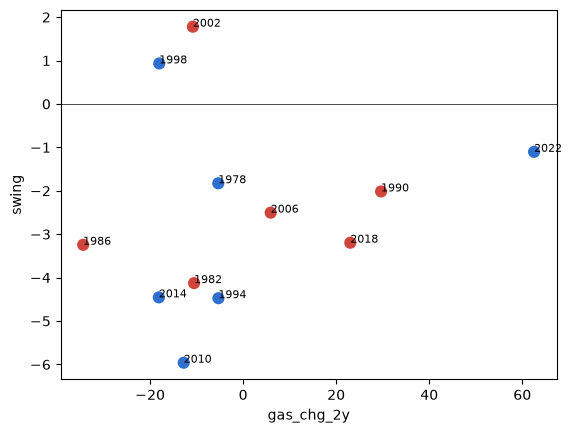

In [2]:
ax = nat.plot.scatter('gas_chg_2y', 'swing', c=nat.pres_party.map({'D':'#2f6fd0','R':'#d0453b'}), s=60)
for _, r in nat.iterrows(): ax.annotate(r.year, (r.gas_chg_2y, r.swing), fontsize=8)
ax.axhline(0, color='k', lw=.5)
nat[['swing','gas_chg_2y','gas_chg_1y','approval','inflation_1y','unemp_chg_2y','crude_chg_2y']].corr()['swing'].round(2)

## 2. National regressions
With n = 12, add one control at a time. Approval is the strongest predictor.

In [3]:
for f in ['swing ~ gas_chg_2y', 'swing ~ gas_chg_2y + approval', 'swing ~ gas_chg_2y + approval + inflation_1y']:
    m = smf.ols(f, nat).fit(cov_type='HC1')
    print(f)
    print(m.summary().tables[1])
    print()

swing ~ gas_chg_2y
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -2.5229      0.681     -3.704      0.000      -3.858      -1.188
gas_chg_2y     0.0140      0.016      0.883      0.377      -0.017       0.045

swing ~ gas_chg_2y + approval
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    -11.0463      2.843     -3.886      0.000     -16.618      -5.475
gas_chg_2y     0.0402      0.018      2.241      0.025       0.005       0.075
approval       0.1725      0.061      2.833      0.005       0.053       0.292

swing ~ gas_chg_2y + approval + inflation_1y
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept      -11.0430      3.

## 3. Is gas a *mediator*? Do gas prices move approval?
If gas prices hurt the president by lowering approval, then controlling for approval removes that channel (a "bad control").

In [4]:
print(smf.ols('approval ~ gas_chg_2y', nat).fit(cov_type='HC1').summary().tables[1])

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     49.4074      2.881     17.150      0.000      43.761      55.054
gas_chg_2y    -0.1521      0.091     -1.673      0.094      -0.330       0.026


## 4. Sensitivity: drop one midterm at a time

In [5]:
pd.DataFrame([{'dropped': y, 'gas_coef': smf.ols('swing ~ gas_chg_2y + approval', nat[nat.year != y]).fit(cov_type='HC1').params['gas_chg_2y']} for y in nat.year]).round(3)

,dropped,gas_coef
0,1978,0.041
1,1982,0.041
2,1986,0.032
3,1990,0.060
4,1994,0.038
5,1998,0.041
6,2002,0.039
7,2006,0.042
8,2010,0.033
9,2014,0.042


## 5. State panel with year fixed effects
Year fixed effects compare states **within the same midterm**, which removes everything national (the president, the mood, national gas price). The remaining question: did states whose gas prices rose *more* swing harder?

In [6]:
df = panel.dropna(subset=['swing','gas_chg_2y','unemp_chg_2y','income_growth_2y'])
m = smf.wls('swing ~ gas_chg_2y + unemp_chg_2y + income_growth_2y + C(year)', df, weights=df.n_districts).fit(cov_type='cluster', cov_kwds={'groups': df.state})
print(m.summary().tables[1].as_text().split('C(year)')[0])
print(m.params.filter(like='gas'), m.pvalues.filter(like='gas'))

                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept            0.0801      1.219      0.066      0.948      -2.309       2.469

gas_chg_2y    0.082547
dtype: float64 gas_chg_2y    0.260473
dtype: float64


## Takeaways
- No robust evidence that gas prices directly cost the president's party House votes.
- Approval explains ~36% of the swing across midterms; gas ~3%.
- Gas may work *through* approval (marginal evidence).
- The positive gas coefficient after controlling for approval is fragile (driven by 2022) and is a textbook bad-control artifact.

Full tables: `reports/results.md`. Interactive version: `dashboard/index.html`.